## Метрический слой и качество данных

На семинаре по детекции аномалий мы работали с готовым файлом: в нем уже был столбец `conversion_rate` по дням, и оставалось выбрать метод. В реальной системе такого файла нет. Прежде чем поставить метрику на мониторинг, нужно ответить на два вопроса:

1. **Откуда берется ряд?** Кто и по какому определению его считает, и получится ли тот же ряд у другой команды.
2. **Можно ли ему верить?** Отражает ли отклонение ряда продукт, а не поломку в таблицах.

На первый вопрос отвечает **метрический слой**, на второй — **контроль качества данных**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 14, 'axes.titlepad': 16,
    'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False,
})

import warnings
warnings.filterwarnings('ignore')

### Данные

Сервис бронирования отелей, 12 недель. Три таблицы:
- df_searches — поиски: пользователь, время, город, устройство;
- df_bookings — бронирования: цена, число ночей, когда запись попала в хранилище (`loaded_at`), когда бронирование отменили (`cancelled_at`, если отменили);
- df_rooms — свободные номера на конец дня по городам.

Данные синтетические. Запись о бронировании попадает в хранилище не сразу, а бронирование могут отменить спустя дни — это понадобится в части про качество.

In [2]:
def generate_booking_data(seed=7):
    rng = np.random.default_rng(seed)
    days = pd.date_range('2025-07-01', periods=84, freq='D')          
    snapshot = days[-1] + pd.Timedelta(days=1)                         

    cities = ['moscow', 'spb', 'kazan', 'sochi']
    price_mult = {'moscow': 1.3, 'spb': 1.1, 'kazan': 0.8, 'sochi': 1.0}
    devices = ['ios', 'android', 'web']
    conv = {'ios': 0.045, 'android': 0.035, 'web': 0.018}             

    n_users = 40_000
    user_city = rng.choice(cities, n_users, p=[0.4, 0.25, 0.15, 0.2])

    searches = []
    for i, d in enumerate(days):
        weekend = d.dayofweek >= 5
        n = int(rng.normal(1800 + 6 * i, 100) * (1.6 if weekend else 1.0))
        web_share = 0.25 + 0.25 * i / len(days)                       
        dev = rng.choice(devices, n, p=[(1 - web_share) * 0.55, (1 - web_share) * 0.45, web_share])
        uid = rng.integers(0, n_users, n)
        ts = d + pd.to_timedelta(rng.uniform(0, 24 * 3600, n), unit='s')
        searches.append(pd.DataFrame({'user_id': uid, 'ts': ts, 'city': user_city[uid], 'device': dev,
                                      'conv_mult': 0.5 if weekend else 1.0}))   
    df_searches = pd.concat(searches, ignore_index=True)
    df_searches.insert(0, 'search_id', np.arange(len(df_searches)))

    booked = rng.random(len(df_searches)) < df_searches.device.map(conv).to_numpy() * df_searches.conv_mult.to_numpy()
    df_searches = df_searches.drop(columns='conv_mult')
    b = df_searches[booked].drop(columns='search_id').copy()
    n = len(b)
    b['nights'] = rng.choice([1, 2, 3, 4, 5, 7], n, p=[0.3, 0.3, 0.15, 0.1, 0.1, 0.05])
    b['price'] = (rng.lognormal(np.log(5500), 0.45, n) * b.city.map(price_mult) * b.nights).round(0)
    b['ts'] = b.ts + pd.to_timedelta(rng.uniform(60, 1800, n), unit='s')

    delay = rng.choice([0, 1, 2, 3, 5], n, p=[0.70, 0.18, 0.06, 0.04, 0.02])
    b['loaded_at'] = b.ts + pd.to_timedelta(delay, unit='D') + pd.to_timedelta(rng.uniform(0.1, 6, n), unit='h')

    cancel = rng.random(n) < 0.12
    cancelled_at = b.ts + pd.to_timedelta(rng.uniform(1, 14, n), unit='D')
    b['cancelled_at'] = cancelled_at.where(cancel & (cancelled_at <= snapshot), pd.NaT)

    b = b[b.loaded_at <= snapshot]                                    
    b = b.sort_values('ts').reset_index(drop=True)
    b.insert(0, 'booking_id', np.arange(len(b)))
    df_bookings = b[['booking_id', 'user_id', 'ts', 'city', 'device', 'nights', 'price', 'loaded_at', 'cancelled_at']]

    rooms = {c: 1200 * m for c, m in zip(cities, [1.0, 0.7, 0.4, 0.5])}
    inv = [{'date': d, 'city': c, 'rooms_available': int(rooms[c] * (0.55 + 0.25 * np.sin(i / 9) + rng.normal(0, 0.03)))}
           for i, d in enumerate(days) for c in cities]
    df_rooms = pd.DataFrame(inv)

    return df_searches, df_bookings, df_rooms, snapshot

In [3]:
df_searches, df_bookings, df_rooms, SNAPSHOT = generate_booking_data()

In [4]:
for df in (df_searches, df_bookings):
    df['date'] = df.ts.dt.normalize()

In [5]:
print(f'Поисков: {len(df_searches):};  бронирований: {len(df_bookings):};  '
      f'период: {df_searches.date.min():%Y-%m-%d} — {df_searches.date.max():%Y-%m-%d};  данные на {SNAPSHOT:%Y-%m-%d}')

Поисков: 202167;  бронирований: 5086;  период: 2025-07-01 — 2025-09-22;  данные на 2025-09-23


In [6]:
df_searches.head()

,search_id,user_id,ts,city,device,date
0,0,4838,2025-07-01 22:09:25.242047808,moscow,ios,2025-07-01
1,1,4056,2025-07-01 21:01:21.565620603,spb,web,2025-07-01
2,2,10267,2025-07-01 15:18:22.228656230,sochi,web,2025-07-01
3,3,11551,2025-07-01 06:28:34.866510810,spb,web,2025-07-01
4,4,31998,2025-07-01 15:34:12.097058091,kazan,ios,2025-07-01


In [7]:
df_searches.city.unique()

array(['moscow', 'spb', 'sochi', 'kazan'], dtype=object)

In [8]:
df_bookings.head()

,booking_id,user_id,ts,city,device,nights,price,loaded_at,cancelled_at,date
0,0,28679,2025-07-01 00:41:55.467849436,moscow,android,1,5193.0,2025-07-01 05:29:27.785062286,NaT,2025-07-01
1,1,5733,2025-07-01 00:50:19.239836683,moscow,ios,2,30315.0,2025-07-01 01:57:18.535410118,NaT,2025-07-01
2,2,4670,2025-07-01 01:28:00.763023448,spb,ios,1,5885.0,2025-07-01 02:35:58.539665858,NaT,2025-07-01
3,3,35953,2025-07-01 01:38:59.893903857,sochi,android,1,6771.0,2025-07-01 05:42:01.683714507,2025-07-09 03:32:56.520234964,2025-07-01
4,4,15736,2025-07-01 02:06:16.895700493,moscow,ios,3,24203.0,2025-07-01 06:53:51.135957704,NaT,2025-07-01


In [9]:
df_rooms.head()

,date,city,rooms_available
0,2025-07-01,moscow,656
1,2025-07-01,spb,429
2,2025-07-01,kazan,259
3,2025-07-01,sochi,326
4,2025-07-02,moscow,663


### Агрегат

Сырых строк двести тысяч, каждый запрос к ним — это потраченное время и деньги. Поэтому метрики считают из агрегата: таблицы, где одна строка — одна комбинация измерений на самом мелком уровне, который понадобится. 

У нас это день, город и устройство — **гранулярность** агрегата.

В каждой строке храним не метрики, а их **компоненты**: суммы и счетчики.

In [10]:
GRAIN = ['date', 'city', 'device']

s = df_searches.groupby(GRAIN).agg(searches=('search_id', 'size'), search_users=('user_id', 'nunique'))
b = df_bookings.groupby(GRAIN).agg(bookings=('booking_id', 'size'), revenue=('price', 'sum'),
                                   nights=('nights', 'sum'), cancelled=('cancelled_at', 'count'))

agg = s.join(b, how='outer').fillna(0).reset_index()

In [11]:
agg.head()

,date,city,device,searches,search_users,bookings,revenue,nights,cancelled
0,2025-07-01,kazan,android,69,68,3.0,38828.0,9.0,0.0
1,2025-07-01,kazan,ios,117,114,4.0,31720.0,7.0,0.0
2,2025-07-01,kazan,web,66,64,0.0,0.0,0.0,0.0
3,2025-07-01,moscow,android,258,258,7.0,149703.0,17.0,0.0
4,2025-07-01,moscow,ios,305,303,18.0,374773.0,51.0,2.0


In [12]:
print(f'Строк в агрегате: {len(agg):}  вместо {len(df_searches) + len(df_bookings):} в сырых таблицах')

Строк в агрегате: 1008  вместо 207253 в сырых таблицах


Двести строк сырых данных на одну строку агрегата. Все метрики ниже будем считать из него и каждый раз проверять, можно ли это делать.

#### Подробнее про гранулярность

**Гранулярность** — самое мелкое сечение «измерение x период», на котором хранится метрика. Какой она может быть, определяет сама метрика:

- **Предел снизу** — зерно (grain) события. Мельче одного заказа или поиска опуститься нельзя. Период по времени задает задача: для операционного мониторинга агрегируют по часам или минутам, для продуктовых и финансовых метрик обычно по дням.
- **Предел сверху** — аддитивность. Гранулярность имеет смысл, если из ее строк собирается любая более крупная. Суммы и счетчики собираются всегда, доли и средние — только из компонентов, уникальные пользователи — ни на какой гранулярности крупнее «пользователь x период».
- **Период** — часть определения. Для остатков и балансов строка *за день* — это значение на конец дня или среднее. Для метрик с окном (WAU, retention) период задается окном, и их хранят готовыми, а не собирают из дневных.

Внутри этих пределов гранулярность выбирают по срезам, которые понадобятся: самая мелкая комбинация измерений, по которым метрику будут смотреть. Укрупнить агрегат можно всегда, раздробить — нет, поэтому в сомнении измерение лучше включить.

### Аддитивность

Метрика **аддитивна**, если ее значение для объединения двух групп равно сумме значений по группам. Выручка аддитивна по любому измерению: выручка за неделю — сумма выручек по дням, выручка по стране — сумма по городам. Такие метрики можно хранить на мелкой грануляции и складывать до любой нужной.

In [13]:
week = agg[agg.date < '2025-07-08']

print(f"Выручка за неделю из агрегата:    {week.revenue.sum():.0f}")
print(f"Выручка за неделю из бронирований: {df_bookings[df_bookings.date < '2025-07-08'].price.sum():.0f}")

Выручка за неделю из агрегата:    6904005
Выручка за неделю из бронирований: 6904005


**Уникальные пользователи — не аддитивны**: один человек ищет отель в понедельник и в среду, и в недельном счетчике он один, а в сумме дневных — два.

In [14]:
wk_searches = df_searches[df_searches.date < '2025-07-08']

print(f"Сумма дневных уникальных пользователей: {week.search_users.sum():.0f}")
print(f"Уникальных пользователей за неделю:     {wk_searches.user_id.nunique():.0f}")

Сумма дневных уникальных пользователей: 14717
Уникальных пользователей за неделю:     12398


In [15]:
round(week.search_users.sum() * 100 / wk_searches.user_id.nunique() - 100)

19

In [16]:
week.head()

,date,city,device,searches,search_users,bookings,revenue,nights,cancelled
0,2025-07-01,kazan,android,69,68,3.0,38828.0,9.0,0.0
1,2025-07-01,kazan,ios,117,114,4.0,31720.0,7.0,0.0
2,2025-07-01,kazan,web,66,64,0.0,0.0,0.0,0.0
3,2025-07-01,moscow,android,258,258,7.0,149703.0,17.0,0.0
4,2025-07-01,moscow,ios,305,303,18.0,374773.0,51.0,2.0


Сумма дневных уникальных на 19% больше недельных. Из столбца `search_users` в агрегате недельное или месячное число уникальных пользователей **не восстановить**. 

Варианты: 
- хранить таблицу «пользователь x день» и считать уникальных из нее;
- хранить готовые счетчики на каждой нужной грануляции (день, неделя, месяц) — наиболее распространенный вариант для метрического слоя;
- хранить вероятностный скетч (HyperLogLog), который умеет объединяться с небольшой погрешностью.

Третий тип — **полуаддитивные** метрики: остатки, балансы, число активных подписок. Они описывают состояние на момент, а не поток за период, поэтому складываются по сегментам, но не по времени: для времени правило задают отдельно. 

Пример: свободные номера складываются по городам, но не по дням.

In [17]:
inv_week = df_rooms[df_rooms.date < '2025-07-08']

print(f"Свободных номеров 2025-07-07, все города:  {inv_week[inv_week.date == '2025-07-07'].rooms_available.sum(): }")
print(f"Сумма по дням недели, все города:          {inv_week.rooms_available.sum(): }  (не имеет смысла)")
print(f"Среднее за неделю, все города:             {inv_week.groupby('date').rooms_available.sum().mean(): .0f}")

Свободных номеров 2025-07-07, все города:   2229
Сумма по дням недели, все города:           13737  (не имеет смысла)
Среднее за неделю, все города:              1962


Для полуаддитивной метрики по времени берут значение на конец периода или среднее — и это нужно зафиксировать в определении.

| Тип | Примеры | По сегментам | По времени | Что хранить |
|---|---|---|---|---|
| аддитивные | выручка, заказы, поиски, ночи | складываются | складываются | сумму на мелкой грануляции |
| полуаддитивные | свободные номера, активные подписки, баланс | складываются | нет: last или avg | значение на каждый день |
| неаддитивные | уникальные пользователи, доли, средние, квантили | нет | нет | компоненты или отдельные таблицы |


**Условие для определения аддитивна ли метрика одно — объекты не должны попадать в несколько групп сразу.**

### Доли: когда делить

Конверсия поиска в бронирование — доля. 

С точки зрения операций, недельную конверсию можно получить двумя способами: усреднить дневные конверсии или разделить сумму бронирований на сумму поисков.

In [18]:
daily = agg.groupby('date')[['bookings', 'searches']].sum()
daily['conversion'] = daily.bookings / daily.searches

week_of = daily.index.to_period('W').start_time
by_week = pd.DataFrame({
    'mean_of_daily': daily.conversion.groupby(week_of).mean(),
    'sum_over_sum': daily.bookings.groupby(week_of).sum() / daily.searches.groupby(week_of).sum(),
})

by_week['diff'] = by_week.mean_of_daily / by_week.sum_over_sum - 1
by_week.head().style.format({'mean_of_daily': '{:.2%}', 'sum_over_sum': '{:.2%}', 'diff': '{:+.1%}'})

,mean_of_daily,sum_over_sum,diff
date,,,
2025-06-30 00:00:00,3.02%,2.73%,+10.6%
2025-07-07 00:00:00,2.64%,2.44%,+8.3%
2025-07-14 00:00:00,2.97%,2.76%,+7.9%
2025-07-21 00:00:00,2.88%,2.73%,+5.6%
2025-07-28 00:00:00,2.79%,2.61%,+6.9%


Разница 6–10%. Посмотрим на одну неделю по дням.

In [19]:
daily['weekday'] = daily.index.day_name()
daily.head(7)[['weekday', 'searches', 'bookings', 'conversion']].style.format({'conversion': '{:.2%}'})

,weekday,searches,bookings,conversion
date,,,,
2025-07-01 00:00:00,Tuesday,1781,60.000000,3.37%
2025-07-02 00:00:00,Wednesday,1732,63.000000,3.64%
2025-07-03 00:00:00,Thursday,1744,70.000000,4.01%
2025-07-04 00:00:00,Friday,1718,68.000000,3.96%
2025-07-05 00:00:00,Saturday,3059,41.000000,1.34%
2025-07-06 00:00:00,Sunday,3034,55.000000,1.81%
2025-07-07 00:00:00,Monday,1785,53.000000,2.97%


В выходные поисков больше, а конверсия вдвое ниже: смотрят многие, а бронируют — нет. Среднее дневных конверсий считает все дни одинаково важными; правильная конверсия взвешивает дни по числу поисков. Выходные с их низкой конверсией весят больше — и недельная конверсия ниже среднего дневных.

То же с любым другим измерением.

In [20]:
by_device = agg.groupby('device')[['bookings', 'searches']].sum()
by_device['conversion'] = by_device.bookings / by_device.searches

In [21]:
by_device.style.format({'conversion': '{:.2%}', 'bookings': '{:.0f}'})

,bookings,searches,conversion
device,,,
android,1560,56242,2.77%
ios,2495,69072,3.61%
web,1031,76853,1.34%


In [22]:
print(f"Среднее конверсий по устройствам:  {by_device.conversion.mean():.2%}")
print(f"Конверсия всех поисков:            {by_device.bookings.sum() / by_device.searches.sum():.2%}")

Среднее конверсий по устройствам:  2.58%
Конверсия всех поисков:            2.52%


Веб дает 38% поисков, но конверсия у него втрое ниже; среднее по трем устройствам этого не знает.

**Правило: долю считают делением сумм, а не усреднением долей.** В агрегате храним числитель и знаменатель, делим в момент запроса. Готовая конверсия в строке агрегата бесполезна: ее нельзя ни сложить, ни усреднить.

### Средние и квантили

Средний чек — устроен так же, как доля: это отношение двух сумм — выручки к числу бронирований. Поэтому и агрегируется он так же — делением сумм, а не усреднением средних. 

Среднее средних чеков по городам отличается от среднего чека по той же причине, что и конверсия: города весят одинаково, хотя бронирований в них разное число.

In [23]:
by_city = agg.groupby('city')[['bookings', 'revenue']].sum()
by_city['avg_price'] = by_city.revenue / by_city.bookings

by_city.round(0).astype(int)

,bookings,revenue,avg_price
city,,,
kazan,723,9320232,12891
moscow,2074,42253730,20373
sochi,1023,15914888,15557
spb,1266,21060891,16636


In [24]:
print(f"Среднее средних чеков по городам: {by_city.avg_price.mean():.0f}")
print(f"Средний чек всех бронирований:    {df_bookings.price.mean():.0f}")

Среднее средних чеков по городам: 16364
Средний чек всех бронирований:    17410


Москва дает 40% бронирований и самый дорогой чек, а среднее по городам считает ее одной из четырех. Расхождение 6%.

С квантилями ситуация сложнее — их нельзя получить ни сложением, ни взвешиванием.

**Что будет, если хранить дневные p90 и из них считать p90 за период?**

In [25]:
daily_p90 = df_bookings.groupby('date').price.quantile(0.9)

print(f"p90 чека за период:              {df_bookings.price.quantile(0.9):.0f}")
print(f"среднее дневных p90:             {daily_p90.mean():.0f}")
print(f"p90 дневных p90:                 {daily_p90.quantile(0.9):.0f}")

p90 чека за период:              35264
среднее дневных p90:             34726
p90 дневных p90:                 41615


Ни среднее дневных p90, ни квантиль квантиля не равны квантилю за период. Квантиль за период — это квантиль распределения всех чеков за период, и из сводных чисел по дням его не восстановить.

Как хранить квантили в агрегате, если сырые данные недоступны? Хранить **гистограмму**: число бронирований в каждой корзине цены. Корзины аддитивны — их можно складывать по дням и городам, а квантиль считать из суммарной гистограммы.

In [26]:
EDGES = np.geomspace(1000, 300_000, 41)
EDGES

array([  1000.        ,   1153.26213042,   1330.01354146,   1533.85425032,
         1768.93602047,   2040.04692355,   2352.70886121,   2713.29003354,
         3129.13464453,   3608.71248653,   4161.79145029,   4799.63647433,
         5535.23898563,   6383.58150495,   7361.94280612,   8490.24984462,
         9791.48362361,  11292.14726374,  13022.80581041,  15018.70877297,
        17320.50807569,  19975.08604334,  23036.51028568,  26567.13492953,
        30638.870628  ,  35334.64921414,  40750.11283037,  46995.56193764,
        54198.20188053,  62504.73376572,  72084.34242404,  83132.14231394,
        95873.15155142, 110566.87500835, 127512.5898261 , 147055.44099833,
       169593.47117571, 195585.72787356, 225561.61320737, 260131.66658869,
       300000.        ])

In [27]:
df_bookings['bucket'] = np.digitize(df_bookings.price, EDGES)
hist = df_bookings.groupby(['date', 'city', 'bucket']).size().rename('n').reset_index()

In [28]:
hist.head()

,date,city,bucket,n
0,2025-07-01,kazan,8,1
1,2025-07-01,kazan,10,1
2,2025-07-01,kazan,12,1
3,2025-07-01,kazan,14,1
4,2025-07-01,kazan,15,1


In [29]:
def quantile_from_hist(hist, q):
    counts = hist.groupby('bucket').n.sum().reindex(range(1, len(EDGES)), fill_value=0)
    cum = counts.cumsum() / counts.sum()
    k = int(cum.searchsorted(q)) + 1
    lo, hi = EDGES[k - 1], EDGES[k]
    below = cum.get(k - 1, 0.0)
    frac = (q - below) / (cum[k] - below) if cum[k] > below else 0.5
    
    return lo + frac * (hi - lo)

In [30]:
print(f'Строк в гистограмме: {len(hist):}  вместо {len(df_bookings):} бронирований')

Строк в гистограмме: 3416  вместо 5086 бронирований


In [31]:
check = []

for name, mask in [('весь период', slice(None)), ('август, sochi', (df_bookings.date.dt.month == 8) & (df_bookings.city == 'sochi'))]:
    raw = df_bookings.loc[mask]
    h = hist[hist.date.isin(raw.date.unique()) & hist.city.isin(raw.city.unique())]
    
    for q in (0.5, 0.9, 0.99):
        check.append({'срез': name, 'квантиль': q, 'точно': raw.price.quantile(q), 'из гистограммы': quantile_from_hist(h, q)})

check = pd.DataFrame(check)
check['ошибка'] = (check['из гистограммы'] / check['точно'] - 1).map('{:+.1%}'.format)
check.round({'точно': 0, 'из гистограммы': 0})

,срез,квантиль,точно,из гистограммы,ошибка
0,весь период,0.50,13060.0,13082.0,+0.2%
1,весь период,0.90,35264.0,35298.0,+0.1%
2,весь период,0.99,68480.0,70399.0,+2.8%
3,"август, sochi",0.50,11225.0,11209.0,-0.1%
4,"август, sochi",0.90,30390.0,30747.0,+1.2%
5,"август, sochi",0.99,69921.0,72720.0,+4.0%


Медиана и p90 восстанавливаются с ошибкой до 1%, p99 — до 4%: в хвосте в корзину попадает мало наблюдений, и предположение о равномерности внутри нее работает хуже. Точность регулируется шириной корзин.

Но ошибка остается, поэтому основной способ другой: квантиль для каждого нужного среза считают из сырых данных и хранят готовым — p90 по дням, p90 по неделям, p90 по городам за месяц. Из готовых квантилей по дням квантиль за неделю не собрать, и каждый уровень считается отдельно.

Гистограмма нужна там, где этот способ не работает: когда срез заранее не известен (произвольный фильтр в дашборде) или сырые данные уже недоступны. Тогда хранят гистограмму на мелкой гранулярности и принимают погрешность.

Промежуточный итог о том, что нельзя восстановить из агрегата по дням:
- уникальных пользователей за период — из дневных уникальных;
- долю или среднее за период — из дневных долей и средних;
- квантиль за период — из дневных квантилей.

Во всех трех случаях нужно хранить не результат, а то, из чего он считается.

### Метрика как код

Если каждый аналитик считает конверсию по-своему, в компании будет несколько конверсий. Метрический слой решает это тем, что **определение метрики хранится в одном месте и в виде кода**: что в числителе, что в знаменателе, из какого агрегата. Все остальное — срезы, периоды, фильтры — параметры запроса.

Минимальный слой: словарь определений и одна функция.

In [32]:
METRICS = {
    'searches':    ('searches', None),
    'bookings':    ('bookings', None),
    'revenue':     ('revenue', None),
    'conversion':  ('bookings', 'searches'),
    'avg_price':   ('revenue', 'bookings'),
    'avg_nights':  ('nights', 'bookings'),
    'cancel_rate': ('cancelled', 'bookings'),
}

In [33]:
def metric(name, agg, by=None, where=None):
    num, den = METRICS[name]
    d = agg.query(where) if where else agg
    cols = [c for c in (num, den) if c]
    total = d.groupby(by)[cols].sum() if by is not None else d[cols].sum()
    
    return total[num] / total[den] if den else total[num]

In [34]:
agg.head()

,date,city,device,searches,search_users,bookings,revenue,nights,cancelled
0,2025-07-01,kazan,android,69,68,3.0,38828.0,9.0,0.0
1,2025-07-01,kazan,ios,117,114,4.0,31720.0,7.0,0.0
2,2025-07-01,kazan,web,66,64,0.0,0.0,0.0,0.0
3,2025-07-01,moscow,android,258,258,7.0,149703.0,17.0,0.0
4,2025-07-01,moscow,ios,305,303,18.0,374773.0,51.0,2.0


In [35]:
print('Конверсия по месяцам:')
print(metric('conversion', agg, by=agg.date.dt.month).map('{:.2%}'.format).to_string())
print('\nКонверсия по устройствам:')
print(metric('conversion', agg, by='device').map('{:.2%}'.format).to_string())

Конверсия по месяцам:
date
7    2.75%
8    2.45%
9    2.32%

Конверсия по устройствам:
device
android    2.77%
ios        3.61%
web        1.34%


In [36]:
web_aug = metric('conversion', agg, where="device == 'web' and date.dt.month == 8")
sochi = metric('avg_price', agg, where="city == 'sochi'")
cancel = metric('cancel_rate', agg)

print(f'conversion, web, август:   {web_aug:.2%}')
print(f'avg_price, sochi:          {sochi:,.0f}')
print(f'cancel_rate, весь период:  {cancel:.1%}')

conversion, web, август:   1.40%
avg_price, sochi:          15,557
cancel_rate, весь период:  10.6%


Один и тот же код дает конверсию по месяцам, по устройствам, по любому фильтру, и всегда делит суммы, а не усредняет доли. Если определение меняется — например, из поисков решили исключить ботов, — оно меняется в одном месте, и все отчеты пересчитываются одинаково.

У определения, кроме формулы, есть метаданные: тип метрики (аддитивная, доля, полуаддитивная с правилом агрегации по времени), измерения, по которым ее можно декомпозировать, владелец и версия. Вместе они образуют **глоссарий метрик** — документ, по которому любой в компании понимает, что именно означает число в отчете.

### Качество: когда число становится окончательным

Агрегат пересчитывается по расписанию. Но данные за день приходят не в тот же день: запись о бронировании попадает в хранилище с задержкой, а отмена приходит спустя дни и меняет уже посчитанную выручку.

**Какой была выручка за день, если смотреть на нее на следующий день? Через неделю?** Восстановим это по `loaded_at` и `cancelled_at`.

In [37]:
def revenue_as_of(df, day, as_of):
    seen = df[(df.date == day) & (df.loaded_at <= as_of)]
    alive = seen.cancelled_at.isna() | (seen.cancelled_at > as_of)
    
    return seen[alive].price.sum()

In [38]:
days = pd.date_range('2025-07-14', '2025-08-31')
lags = [0, 1, 2, 3, 5, 7, 10, 14]

maturity = pd.DataFrame({
    lag: [revenue_as_of(df_bookings, d, d + pd.Timedelta(days=lag + 1)) / revenue_as_of(df_bookings, d, SNAPSHOT) for d in days]
    for lag in lags
}, index=days)

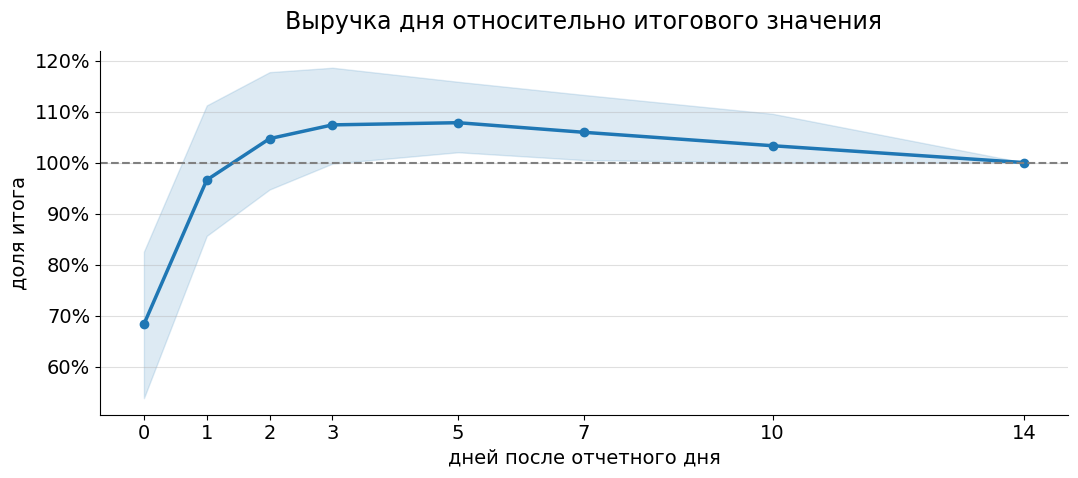

In [39]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(lags, maturity.mean(), marker='o', lw=2.5, color='#1f77b4')
ax.fill_between(lags, maturity.quantile(0.05), maturity.quantile(0.95), alpha=0.15, color='#1f77b4')
ax.axhline(1, color='grey', ls='--', lw=1.5)
ax.set_title('Выручка дня относительно итогового значения')
ax.set_xlabel('дней после отчетного дня'); ax.set_ylabel('доля итога')
ax.set_xticks(lags)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [40]:
maturity.mean().map('{:.1%}'.format).to_frame('доля итога').T

,0,1,2,3,5,7,10,14
доля итога,68.3%,96.6%,104.7%,107.4%,107.8%,105.9%,103.3%,100.0%


Что видим?

- **На следующее утро видно 68% итоговой выручки**: треть записей еще не загрузилась.
- **Через два дня — 105%, через пять — 108%**: записи пришли, а отмены еще нет. Метрика переоценена.
- **К 14-му дню — 100%**: отмены отработали, число стало окончательным.

Выручка за день меняется две недели. Отсюда три правила, которые обычно фиксируют в регламенте пересчета:

1. **Окно пересчета.** Ежедневный расчет пересчитывает не только вчера, а последние N дней, где N — срок, за который метрика становится окончательной. У нас это 14 дней. Дни старше N замораживаются.
2. **Полнота перед публикацией.** День показывается в отчетах, когда пришла заданная доля ожидаемого объема. Пока записей меньше, день помечается как неполный.
3. **Версия определения.** Если меняется определение метрики или находится ошибка в источнике, пересчитывается вся история, а не окно, и у агрегата меняется версия.

Срок N зависит от источника: у поисков из приложения задержка часы, у бронирований с отменами — недели, у платежей с возвратами — месяцы.

### Качество: проверки

Регламент пересчета защищает от задержек. От ошибок в данных защищают **проверки**, которые запускаются при каждом расчете. Возьмем сырую таблицу, в которой что-то сломалось, и соберем набор стандартных проверок.

In [41]:
raw = df_bookings.drop(columns='bucket').copy()

bad_day = raw.date == '2025-08-20'
raw.loc[bad_day & (np.random.default_rng(1).random(len(raw)) < 0.35), 'device'] = None

dup = raw[raw.date == '2025-09-10'].copy()
dup['loaded_at'] = dup.loaded_at + pd.Timedelta(days=1)
raw = pd.concat([raw, dup], ignore_index=True)

raw_agg = raw.groupby(GRAIN).agg(bookings=('booking_id', 'size'), revenue=('price', 'sum')).reset_index()
print(f'Строк: {len(raw):}  (было {len(df_bookings):})')

Строк: 5139  (было 5086)


In [42]:
def run_checks(raw, raw_agg, now):
    results = []

    def add(check, value, threshold, ok, detail=''):
        results.append({'проверка': check, 'значение': value, 'порог': threshold, 'статус': 'OK' if ok else 'FAIL', 'детали': detail})

    lag_h = (now - raw.loaded_at.max()).total_seconds() / 3600
    add('freshness', f'{lag_h:.0f} ч', '< 24 ч', lag_h < 24)

    dups = raw.booking_id.duplicated().sum()
    add('uniqueness: booking_id', int(dups), '0', dups == 0,
        ', '.join(str(d.date()) for d in raw[raw.booking_id.duplicated(keep=False)].date.unique()))

    null_share = raw.groupby('date').device.apply(lambda s: s.isna().mean())
    add('nulls: device', f'{null_share.max():.0%}', '< 1%', null_share.max() < 0.01,
        ', '.join(str(d.date()) for d in null_share[null_share >= 0.01].index))

    bad = set(raw.city.dropna()) - {'moscow', 'spb', 'kazan', 'sochi'}
    add('accepted values: city', len(bad), '0', not bad, ', '.join(bad))

    n = raw.groupby('date').size()
    expected = n.groupby(n.index.dayofweek).transform(lambda s: s.rolling(4, min_periods=2).median().shift(1))
    dev = (n / expected - 1).dropna()
    complete = dev[dev.index < now.normalize() - pd.Timedelta(days=1)]
    outliers = complete[complete.abs() > 0.5]
    add('volume: bookings per day', f'{complete.abs().max():+.0%}', '± 50%', outliers.empty,
        ', '.join(f'{d.date()} ({v:+.0%})' for d, v in outliers.items()))

    last = now.normalize() - pd.Timedelta(days=1)
    share = n.get(last, 0) / expected.get(last, np.nan)
    add('completeness: last day', f'{share:.0%}', '> 90%', share > 0.9, str(last.date()))

    diff = raw_agg.revenue.sum() - raw.price.sum()
    add('reconciliation: revenue', f'{diff:,.0f}', '0', abs(diff) < 1)

    return pd.DataFrame(results)

In [43]:
run_checks(raw, raw_agg, now=SNAPSHOT + pd.Timedelta(hours=9))

,проверка,значение,порог,статус,детали
0,freshness,9 ч,< 24 ч,OK,
1,uniqueness: booking_id,53,0,FAIL,2025-09-10
2,nulls: device,29%,< 1%,FAIL,2025-08-20
3,accepted values: city,0,0,OK,
4,volume: bookings per day,+74%,± 50%,FAIL,2025-09-10 (+74%)
5,completeness: last day,87%,> 90%,FAIL,2025-09-22
6,reconciliation: revenue,"-317,571",0,FAIL,


Проверки, которые есть почти в любом наборе:

- **freshness** — когда пришла последняя запись, ловит остановившуюся загрузку.
- **uniqueness** — дубли ключа: здесь выгрузка за 10 сентября загрузилась дважды, 53 бронирования задвоились.
- **nulls** — пропуски в обязательных полях: 20 августа у 29% бронирований не записалось устройство.
- **accepted values** — только допустимые значения в измерениях.
- **volume** — объем дня против того же дня недели за прошлые недели: 10 сентября +74% из-за дублей. Порог зависит от шума метрики: для 60 бронирований в день +/- 50%.
- **completeness** — последний день еще неполный: пришло 87% ожидаемого. Это не ошибка, а сигнал подсвечивать не полноту данных.
- **reconciliation** — сверка агрегата с источником: сумма выручки в агрегате на 318 тысяч меньше, чем в сырых данных. **Откуда расхождение?**

Группировка по измерениям молча выбросила строки, где устройство не заполнено: `groupby` по умолчанию отбрасывает пропуски в ключе. Пропуски 20 августа не просто испортили разрез по устройствам — они уменьшили выручку всего дня. Сверка ловит это даже тогда, когда проверка на пропуски не настроена.

In [44]:
print(f"Выручка 2025-09-10 в сыром срезе:       {raw[raw.date == '2025-09-10'].price.sum():.0f}")
print(f"Выручка 2025-09-10 после дедупликации:  {raw.drop_duplicates('booking_id')[lambda d: d.date == '2025-09-10'].price.sum():.0f}")

Выручка 2025-09-10 в сыром срезе:       1935718
Выручка 2025-09-10 после дедупликации:  967859


Без проверок выручка 10 сентября была бы завышена вдвое, а 20 августа занижена на треть, и обе ошибки попали бы в отчеты как факт. Проверки запускают до публикации агрегата: при провале критичной проверки расчет останавливается, при провале предупреждающей — агрегат публикуется с пометкой.

### Саммари

- **Агрегат хранит компоненты, а не метрики.** Суммы и счетчики аддитивны и собираются в любой срез. Доли, средние и квантили считаются из компонентов в момент запроса.
- **Из сводных значений по дням не восстановить не аддитивные метрики**: уникальных пользователей, доли, средние и квантили за период. Для них нужны отдельные таблицы, гистограммы.
- **Доля считается делением сумм, а не усреднением долей:** иначе все дни и сегменты весят одинаково, хотя их объемы разные.
- **Определение метрики живет в коде в одном месте.** Срезы и периоды — параметры, а не новые определения.
- **Число за день становится окончательным не сразу.** Регламент фиксирует окно пересчета, порог полноты для публикации и версию определения.
- **Проверки запускаются при каждом расчете:** свежесть, уникальность, пропуски, допустимые значения, объем, полнота, сверка с источником.